# Walkthrough: from the HDF5 database to an analysis

This notebook shows, step by step, how the lab's biomechanics data are stored and analyzed in Python once they are in one HDF5 file.

> **All data here are synthetic.** It uses `demo/demo_database.h5`, made by `make_demo_database.py` from simple models of a counter-movement jump and a squat, with no real subject data. The values are plausible but invented. The patterns the analyses find (sex difference, limb asymmetry, depth vs height) were **built into the generator** to have something to show, so they demonstrate the method, not findings. The file layout and every line of code are identical for the real database: change `DB` in step 0 and nothing else changes.

**Steps**
0. Setup
1. What's in the database
2. Inside the HDF5 file
3. Subjects
4. One trial: a curve with its events
5. Every trial, time-normalized
6. Metrics: one row per trial
7. Body-weight normalization and limb symmetry
8. A relationship between variables
9. Squats: bilateral vs single-leg
10. Exporting for SPSS / R / Excel
11. Using the real data, and MATLAB

## 0. Setup
`v3d_db.py` (in the repository root) does all the reading. `DB` points at the file to use.

In [1]:
import sys
sys.path.insert(0, "..")            # repository root, where v3d_db.py lives

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import v3d_db as db

DB = "../demo/demo_database.h5"     # real data: "../database/rtp_database.h5"

# plotting defaults: thin lines, light grid, fixed colour order
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9890"
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "lines.linewidth": 2, "legend.frameon": False})
pd.set_option("display.precision", 3)

## 1. What's in the database
One call summarizes it: subjects, sessions and trials for each movement, and how many signals, metrics and events each trial carries.

In [2]:
db.summary(db_path=DB);

12 subjects, 12 sessions, 144 trials

             movement   variant  subjects  sessions  trials  signals  metrics  events
counter-movement-jump bilateral        12        12      36       10       14       9
            squatting bilateral        12        12      36       10        5       7
            squatting      left        12        12      36       10        5       7
            squatting     right        12        12      36       10        5       7


## 2. Inside the HDF5 file
The file is organised like folders: `subjects / ID / session / movement / variant / trial / signals`. Each signal is an array of *frames × components (X, Y, Z)*. There are also flat `tables` (trials, events, metrics) across **all** subjects. That's what makes comparing everyone quick. You rarely need to touch this directly, since `v3d_db` handles it, but it helps to see it once.

In [3]:
import h5py

with h5py.File(DB, "r") as f:
    print(f.attrs["note"], "\n")
    subject = sorted(f["subjects"])[0]
    trial = f[f"subjects/{subject}"]
    session = list(trial)[0]
    print(f"subjects/{subject}/{session}/")
    for movement in trial[session]:
        for variant in trial[f"{session}/{movement}"]:
            print(f"    {movement}/{variant}/  ->", ", ".join(trial[f"{session}/{movement}/{variant}"]))
    first = trial[f"{session}/counter-movement-jump/bilateral/trial_01/signals/LINK_MODEL_BASED/ORIGINAL"]
    print("\n  one trial's signals:")
    for name, ds in first.items():
        print(f"    {name:20} shape {ds.shape}  components {ds.attrs['components']}")
    print("\n  tables:", list(f["tables"]))

FULLY SYNTHETIC demo data generated by make_demo_database.py - no real subject data 

subjects/DEMO_001/2026-08-24_markerless/
    counter-movement-jump/bilateral/  -> trial_01, trial_02, trial_03
    squatting/bilateral/  -> trial_01, trial_02, trial_03
    squatting/left/  -> trial_01, trial_02, trial_03
    squatting/right/  -> trial_01, trial_02, trial_03

  one trial's signals:
    Left Ankle Angles    shape (657, 3)  components XYZ
    Left GRF             shape (657, 3)  components XYZ
    Left Hip Angles      shape (657, 3)  components XYZ
    Left Knee Angles     shape (657, 3)  components XYZ
    Left Knee Moment     shape (657, 3)  components XYZ
    Right Ankle Angles   shape (657, 3)  components XYZ
    Right GRF            shape (657, 3)  components XYZ
    Right Hip Angles     shape (657, 3)  components XYZ
    Right Knee Angles    shape (657, 3)  components XYZ
    Right Knee Moment    shape (657, 3)  components XYZ

  tables: ['events', 'metrics', 'trials']


## 3. Subjects
Only non-identifying details are stored: ID, sex, dominance, height, weight, injured side. Names, dates of birth and contact details are never read into the database.

In [4]:
subjects = db.sessions(db_path=DB)[["subject", "date", "system", "sex", "height_m", "weight_kg", "injured_side"]]
subjects.head()

,subject,date,system,sex,height_m,weight_kg,injured_side
0,DEMO_001,2026-08-24,markerless,Female,1.715,61.372,Left
1,DEMO_002,2026-08-26,markerless,Female,1.618,74.193,Left
2,DEMO_003,2026-06-10,markerless,Male,1.779,71.265,Left
3,DEMO_004,2026-06-24,markerless,Male,1.709,80.840,Left
4,DEMO_005,2026-07-23,markerless,Female,1.688,61.080,Right


## 4. One trial: a curve with its events
`load_signal` returns one trial's signal as a table (time, frame, X, Y, Z). Events give the phase boundaries, here movement start, take-off and touch-down.

In [5]:
cmj = db.trials("counter-movement-jump", db_path=DB)
trial_path = cmj.trial_path[0]

knee = db.load_signal(trial_path, "Left Knee Angles", db_path=DB)
events = db.events(db_path=DB).query("trial_path == @trial_path").set_index("name")["time"]
print(knee.head(3), "\n")
print(events[["LeftPlotStart", "TakeOff", "TouchDown", "LeftPlotEnd"]])

    time  frame      X      Y      Z
0  0.000    1.0  5.042 -0.265 -0.237
1  0.005    2.0  5.177 -0.216 -0.477
2  0.010    3.0  5.188 -0.270 -0.434 

name
LeftPlotStart    0.955
TakeOff          1.755
TouchDown        2.184
LeftPlotEnd      2.984
Name: time, dtype: float64


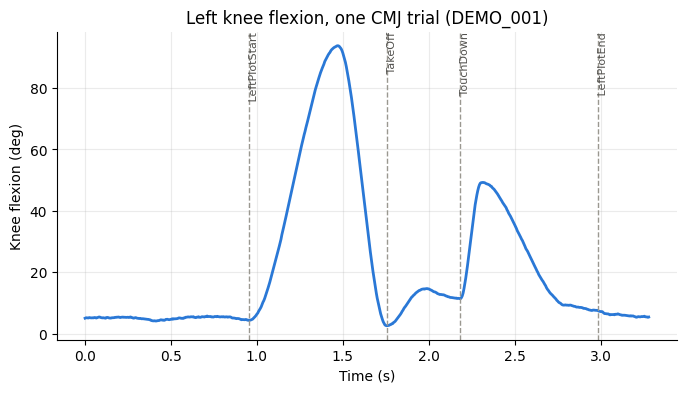

In [6]:
fig, ax = plt.subplots()
ax.plot(knee.time, knee.X, color=BLUE)
for name in ["LeftPlotStart", "TakeOff", "TouchDown", "LeftPlotEnd"]:
    ax.axvline(events[name], color=GREY, lw=1, ls="--")
    ax.text(events[name], ax.get_ylim()[1], f" {name}", rotation=90, va="top", fontsize=8, color="#52514e")
ax.set(xlabel="Time (s)", ylabel="Knee flexion (deg)", title=f"Left knee flexion, one CMJ trial ({cmj.subject[0]})");

## 5. Every trial, time-normalized
`curves` cuts every trial between two events and resamples it to 0–100 %, so trials of different lengths line up. Here: every CMJ of every subject, averaged per subject (thin grey), then across subjects (mean ± 1 SD).

36 trials from 12 subjects


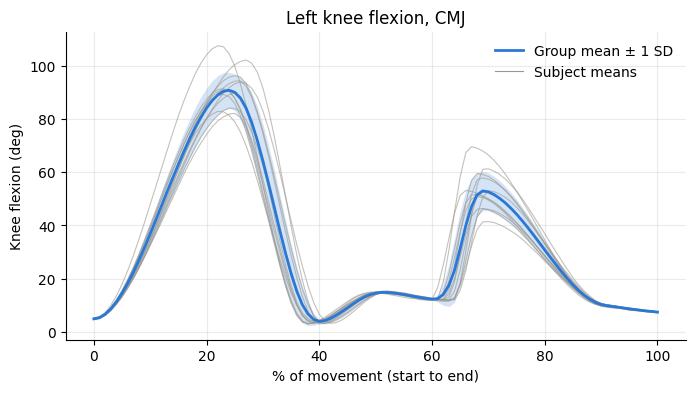

In [7]:
curves = db.curves("counter-movement-jump", "Left Knee Angles", component="X",
                   start_event="LeftPlotStart", end_event="LeftPlotEnd", db_path=DB)
print(f"{curves.trial_path.nunique()} trials from {curves.subject.nunique()} subjects")

per_subject = curves.groupby(["subject", "x"])["value"].mean().unstack("subject")   # 101 x n_subjects
group_mean, group_sd = per_subject.mean(axis=1), per_subject.std(axis=1)

fig, ax = plt.subplots()
ax.plot(per_subject.index, per_subject.values, color=GREY, lw=0.8, alpha=0.6)
ax.fill_between(group_mean.index, group_mean - group_sd, group_mean + group_sd, color=BLUE, alpha=0.2, lw=0)
ax.plot(group_mean.index, group_mean, color=BLUE, label="Group mean ± 1 SD")
ax.plot([], [], color=GREY, lw=0.8, label="Subject means")
ax.set(xlabel="% of movement (start to end)", ylabel="Knee flexion (deg)", title="Left knee flexion, CMJ")
ax.legend();

## 6. Metrics: one row per trial
`metrics_wide` gives one row per trial and one column per metric (jump height, peak angles, peak forces…), ready for statistics. Averaging the three trials gives one row per subject.

In [8]:
m = db.metrics_wide("counter-movement-jump", db_path=DB)
print(m.shape, "(trials x columns)")
cols = ["Jump_height_CMJ", "FlightTime_CMJ", "Left Knee Angles_max_CMJ", "Right Knee Angles_max_CMJ"]
m[["subject", "trial"] + cols].head(6)

(36, 19) (trials x columns)


column,subject,trial,Jump_height_CMJ,FlightTime_CMJ,Left Knee Angles_max_CMJ,Right Knee Angles_max_CMJ
0,DEMO_001,1,0.226,0.429,93.779,92.430
1,DEMO_001,2,0.231,0.434,94.489,94.366
2,DEMO_001,3,0.229,0.432,95.271,98.739
3,DEMO_002,1,0.225,0.429,81.880,81.917
4,DEMO_002,2,0.237,0.439,82.910,79.954
5,DEMO_002,3,0.193,0.397,82.898,83.402


In [9]:
subject_means = m.groupby("subject")[cols].mean().join(subjects.set_index("subject")[["sex", "weight_kg", "injured_side"]])
subject_means.groupby("sex")[cols].agg(["mean", "std"]).round(3).T

sex                             Female    Male
Jump_height_CMJ           mean   0.259   0.349
                          std    0.040   0.051
FlightTime_CMJ            mean   0.458   0.532
                          std    0.036   0.039
Left Knee Angles_max_CMJ  mean  93.462  91.633
                          std    6.780   8.569
Right Knee Angles_max_CMJ mean  93.272  90.244
                          std    8.049   8.599

## 7. Body-weight normalization and limb symmetry
Forces are stored in newtons, so divide by body weight from the subject table. Then compare each subject's **injured** and **uninjured** limb using the limb symmetry index (LSI = injured ÷ uninjured × 100), a common return-to-play measure.

In [10]:
s = subject_means.join(m.groupby("subject")[["Left GRF_max_landing_CMJ_Z", "Right GRF_max_landing_CMJ_Z"]].mean())
bw = s["weight_kg"] * 9.81
s["grf_left_bw"]  = s["Left GRF_max_landing_CMJ_Z"]  / bw
s["grf_right_bw"] = s["Right GRF_max_landing_CMJ_Z"] / bw
s["injured"]   = np.where(s.injured_side == "Left", s.grf_left_bw, s.grf_right_bw)
s["uninjured"] = np.where(s.injured_side == "Left", s.grf_right_bw, s.grf_left_bw)
s["LSI_%"] = 100 * s.injured / s.uninjured

t = stats.ttest_rel(s.injured, s.uninjured)
print(f"Peak landing GRF: injured {s.injured.mean():.2f} BW vs uninjured {s.uninjured.mean():.2f} BW "
      f"(paired t = {t.statistic:.2f}, p = {t.pvalue:.4f})")
print(f"LSI: mean {s['LSI_%'].mean():.1f} %, {int((s['LSI_%'] < 90).sum())} of {len(s)} subjects below 90 %")
s[["injured_side", "injured", "uninjured", "LSI_%"]].round(2)

Peak landing GRF: injured 2.05 BW vs uninjured 2.39 BW (paired t = -10.70, p = 0.0000)
LSI: mean 85.8 %, 11 of 12 subjects below 90 %


,injured_side,injured,uninjured,LSI_%
subject,,,,
DEMO_001,Left,2.09,2.47,84.64
DEMO_002,Left,1.98,2.31,85.43
DEMO_003,Left,2.25,2.70,83.16
DEMO_004,Left,1.80,2.24,80.12
DEMO_005,Right,2.57,3.04,84.37
DEMO_006,Left,1.69,1.91,88.71
DEMO_007,Left,2.82,3.24,87.12
DEMO_008,Right,1.05,1.13,92.58
DEMO_009,Left,2.54,2.86,88.93


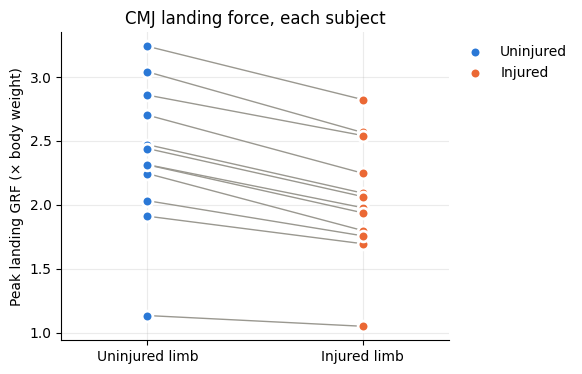

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
for _, r in s.iterrows():
    ax.plot([0, 1], [r.uninjured, r.injured], color=GREY, lw=1)
ax.scatter(np.zeros(len(s)), s.uninjured, color=BLUE, s=60, zorder=3, edgecolor="white", lw=2, label="Uninjured")
ax.scatter(np.ones(len(s)), s.injured, color=ORANGE, s=60, zorder=3, edgecolor="white", lw=2, label="Injured")
ax.set(xticks=[0, 1], xticklabels=["Uninjured limb", "Injured limb"], xlim=(-0.4, 1.4),
       ylabel="Peak landing GRF (× body weight)", title="CMJ landing force, each subject")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

## 8. A relationship between variables
For example, does a deeper countermovement go with a higher jump? Average left and right peak knee flexion per subject and correlate it with jump height.

r = 0.37, p = 0.232  (n = 12)


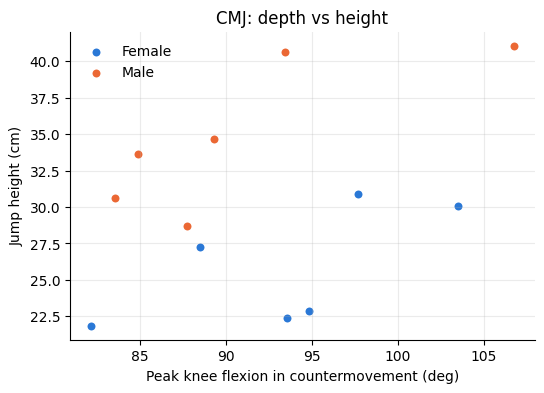

In [12]:
s["knee_flex_max"] = s[["Left Knee Angles_max_CMJ", "Right Knee Angles_max_CMJ"]].mean(axis=1)
r = stats.pearsonr(s.knee_flex_max, s.Jump_height_CMJ)
print(f"r = {r.statistic:.2f}, p = {r.pvalue:.3f}  (n = {len(s)})")

fig, ax = plt.subplots(figsize=(6, 4))
for sex, color in [("Female", BLUE), ("Male", ORANGE)]:
    g = s[s.sex == sex]
    ax.scatter(g.knee_flex_max, g.Jump_height_CMJ * 100, color=color, s=60, edgecolor="white", lw=2, label=sex)
ax.set(xlabel="Peak knee flexion in countermovement (deg)", ylabel="Jump height (cm)", title="CMJ: depth vs height")
ax.legend();

## 9. Squats: bilateral vs single-leg
The same functions work for any movement. Squats have three variants. Compare peak knee flexion of the standing leg.

In [13]:
sq = db.metrics("squatting", db_path=DB)
knee_sq = sq[sq.name.str.contains("Knee Angles_max_Squat")].copy()
knee_sq["leg"] = knee_sq.name.str.split().str[0].str.lower()
# for single-leg squats keep only the standing leg
knee_sq = knee_sq[(knee_sq.variant == "bilateral") | (knee_sq.variant == knee_sq.leg)]
knee_sq.groupby(["variant", "leg"])["value"].agg(["count", "mean", "std"]).round(1)

count   mean   std
variant   leg                      
bilateral left      36   98.4   9.5
          right     36  101.1  11.2
left      left      36   71.0   6.7
right     right     36   72.5   9.1

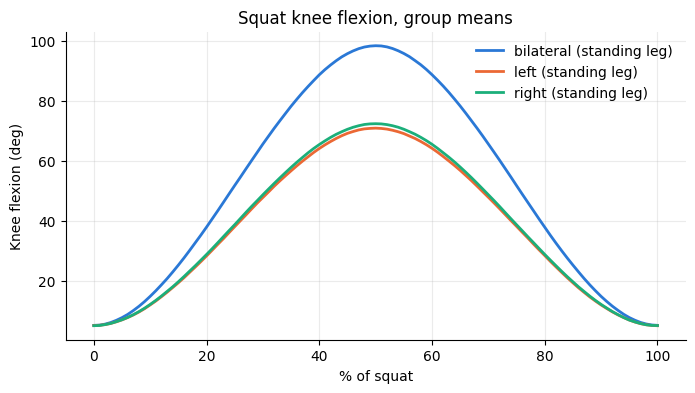

In [14]:
fig, ax = plt.subplots()
for variant, color in [("bilateral", BLUE), ("left", ORANGE), ("right", AQUA)]:
    c = db.curves("squatting", "Left Knee Angles" if variant != "right" else "Right Knee Angles",
                  variant=variant, start_event="LeftPlotStart", end_event="LeftPlotEnd", db_path=DB)
    mean = c.groupby("x")["value"].mean()
    ax.plot(mean.index, mean.values, color=color, label=f"{variant} (standing leg)")
ax.set(xlabel="% of squat", ylabel="Knee flexion (deg)", title="Squat knee flexion, group means")
ax.legend();

## 10. Exporting for SPSS / R / Excel
Any table can be written to CSV. Here: one row per subject with the variables computed above.

In [15]:
from pathlib import Path
out = Path("../demo/exports"); out.mkdir(exist_ok=True)
export = s[["sex", "weight_kg", "injured_side", "Jump_height_CMJ", "knee_flex_max", "injured", "uninjured", "LSI_%"]]
export.round(4).to_csv(out / "cmj_subject_summary.csv")
print("wrote", out / "cmj_subject_summary.csv")
export.round(3).head(3)

wrote ..\demo\exports\cmj_subject_summary.csv


,sex,weight_kg,injured_side,Jump_height_CMJ,knee_flex_max,injured,uninjured,LSI_%
subject,,,,,,,,
DEMO_001,Female,61.372,Left,0.228,94.846,2.091,2.471,84.637
DEMO_002,Female,74.193,Left,0.219,82.160,1.977,2.314,85.428
DEMO_003,Male,71.265,Left,0.287,87.730,2.247,2.702,83.157


## 11. Using the real data, and MATLAB

**Real data.** Build the database from the Qualisys/V3D session exports, then point `DB` at it. Nothing else changes.
```bash
python rtp_ingest.py "path\to\RTP-Assessment\Data"     # -> database/rtp_database.h5
```
```python
DB = "../database/rtp_database.h5"
```
The real database uses the V3D signal and metric names from the RTP-Assessment pipelines (e.g. `Left Knee Angles`, `FlightTime_CMJ_B`). The demo uses the same signal names and similar metric names.

**Confidentiality.** The real database and its source folders stay on lab storage and are excluded from the repository (`.gitignore`). Only this synthetic demo is shareable.

**MATLAB.** HDF5 is read natively; arrays come back transposed (components × frames).
```matlab
f = 'demo/demo_database.h5';
h5disp(f, '/subjects/DEMO_001', 'min')
knee = h5read(f, '/subjects/DEMO_001/<date>_markerless/counter-movement-jump/bilateral/trial_01/signals/LINK_MODEL_BASED/ORIGINAL/Left Knee Angles')';
```

**Dashboard.** `streamlit run dashboard.py` browses the same file interactively (the demo database is selectable in the sidebar).